# 03 阈值策略与测试集评估

- 阈值比较与选择由 `python -m src.policy` 在**验证集**上完成，结果在 `reports/policy_results.json`，锁定的策略在 `models/policy.json`。
- 测试集评估由 `python -m src.evaluate` 完成，结果在 `reports/test_results.json`。

本 notebook 只读取这两个结果文件作图，不加载测试集数据。

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
P = json.loads((ROOT / "reports" / "policy_results.json").read_text(encoding="utf-8"))
T = json.loads((ROOT / "reports" / "test_results.json").read_text(encoding="utf-8"))
T1, T2 = P["chosen"]
CAP, MAXDR = P["constraints"]["review_capacity"], P["constraints"]["max_pass_default_rate"]

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 200, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})
save = lambda fig, name: fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
pct = lambda v, _=None: f"{v:.0%}"
print(f"锁定策略：t1 = {T1}, t2 = {T2}；约束：复核率 ≤ {CAP:.0%}，通过组违约率 ≤ {MAXDR:.0%}")

锁定策略：t1 = 0.15, t2 = 0.4；约束：复核率 ≤ 30%，通过组违约率 ≤ 10%


## 表 1 验证集上三组候选阈值

In [2]:
cand = pd.DataFrame(P["candidates"])
show = cand[["t1", "t2", "n_pass", "n_review", "n_suspend", "pass_rate", "review_rate", "suspend_rate",
             "pass_default_rate", "review_default_rate", "suspend_default_rate",
             "high_recall", "false_block_rate", "leak_rate", "ok_capacity", "ok_default"]]
show.round(4)

,t1,t2,n_pass,n_review,n_suspend,pass_rate,review_rate,suspend_rate,pass_default_rate,review_default_rate,suspend_default_rate,high_recall,false_block_rate,leak_rate,ok_capacity,ok_default
0,0.10,0.3,1366,2217,917,0.3036,0.4927,0.2038,0.0769,0.1637,0.5747,0.5296,0.1113,0.1055,False,True
1,0.15,0.4,2510,1348,642,0.5578,0.2996,0.1427,0.0936,0.2485,0.6620,0.4271,0.0619,0.2362,True,True
2,0.20,0.5,3066,935,499,0.6813,0.2078,0.1109,0.1132,0.3102,0.7174,0.3598,0.0402,0.3487,True,False


## 图 13 三组候选阈值的分档结果与约束（验证集）

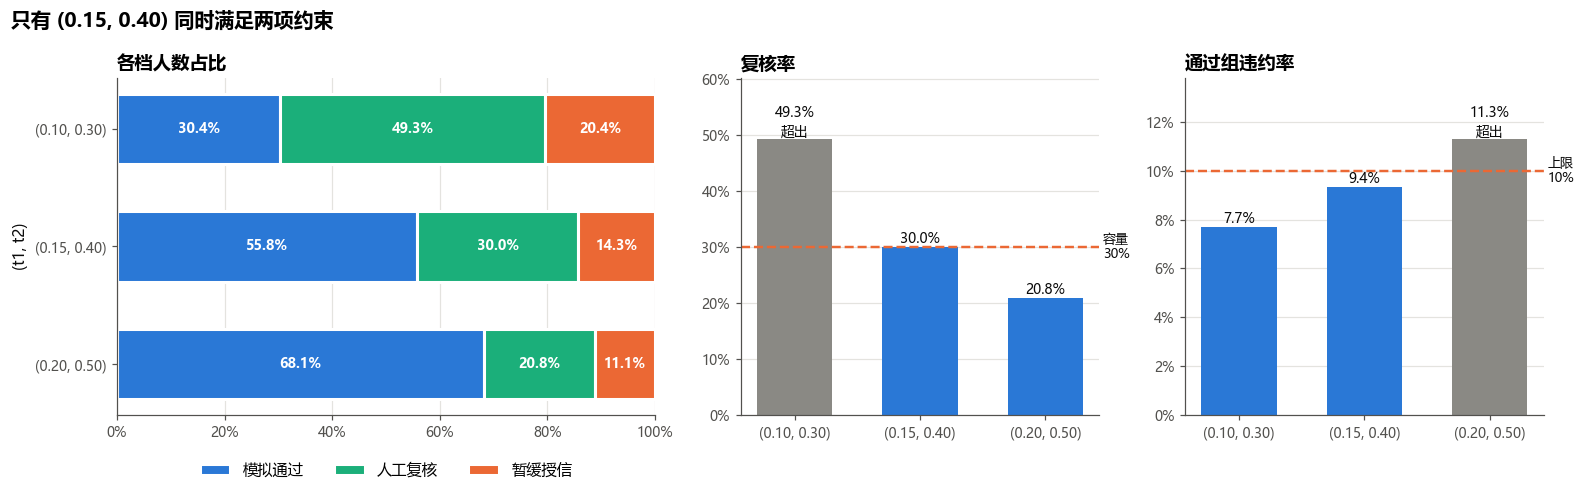

In [3]:
labels = [f"({c['t1']:.2f}, {c['t2']:.2f})" for c in P["candidates"]]
chosen_i = [i for i, c in enumerate(P["candidates"]) if (c["t1"], c["t2"]) == (T1, T2)][0]
fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.6), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))

ax = axs[0]; left = np.zeros(3)
for key, name, col in [("pass", "模拟通过", BLUE), ("review", "人工复核", AQUA), ("suspend", "暂缓授信", ORANGE)]:
    v = cand[f"{key}_rate"].to_numpy()
    ax.barh(labels, v, left=left, color=col, height=0.6, edgecolor="white", linewidth=2, label=name)
    for i, (l, w) in enumerate(zip(left, v)):
        ax.text(l + w / 2, i, f"{w:.1%}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    left += v
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set_title("各档人数占比", loc="left"); ax.set_ylabel("(t1, t2)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)

def constraint_panel(ax, col, limit, title, limit_label):
    v = cand[col].to_numpy()
    ax.bar(labels, v, width=0.6, color=[BLUE if x <= limit else GRAY for x in v])
    ax.axhline(limit, color=ORANGE, lw=1.6, ls="--")
    ax.text(1.01, limit, limit_label, transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.5, color=INK)
    for i, x in enumerate(v):
        ax.text(i, x, f"{x:.1%}" + ("" if x <= limit else "\n超出"), ha="center", va="bottom", fontsize=9, color=INK)
    ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, max(v.max(), limit) * 1.22); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left")

constraint_panel(axs[1], "review_rate", CAP, "复核率", f"容量\n{CAP:.0%}")
constraint_panel(axs[2], "pass_default_rate", MAXDR, "通过组违约率", f"上限\n{MAXDR:.0%}")
fig.suptitle(f"只有 {labels[chosen_i]} 同时满足两项约束", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(); save(fig, "fig13_threshold_candidates"); plt.show()

## 图 14 阈值连续变化时的权衡（验证集，仅作展示，不参与选择）

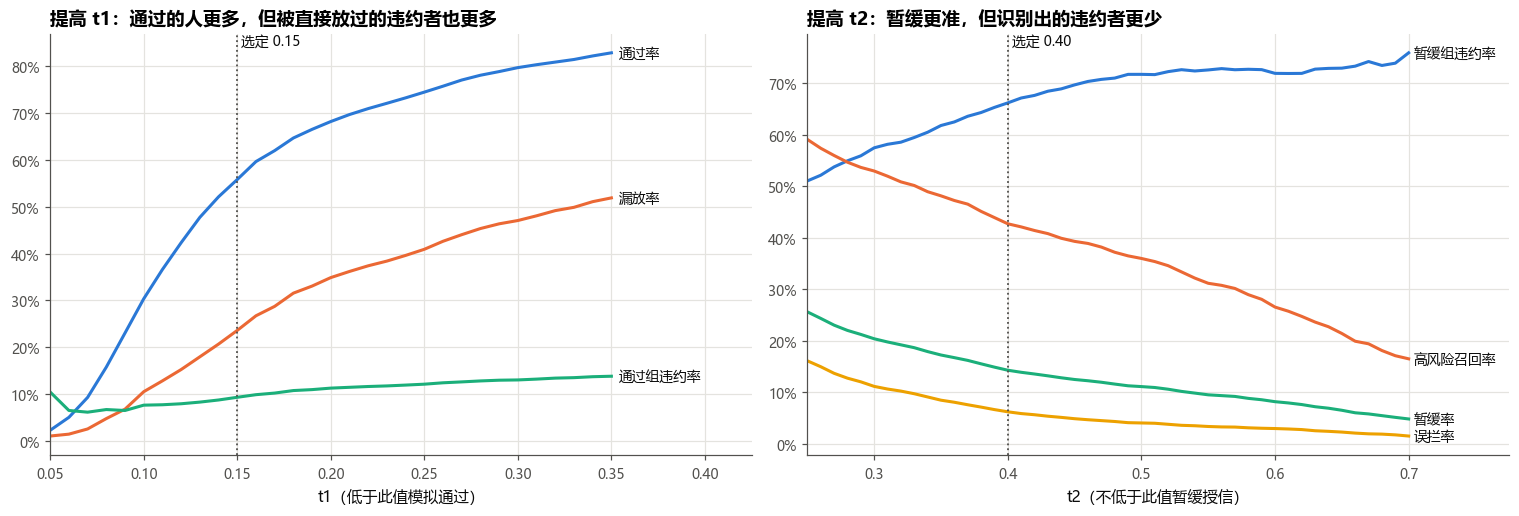

In [4]:
s1, s2 = pd.DataFrame(P["sweep_t1"]), pd.DataFrame(P["sweep_t2"])
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))

def lines(ax, df, x, specs, chosen, title, xlabel):
    for col, name, colr in specs:
        ax.plot(df[x], df[col], color=colr, lw=2)
        ax.text(df[x].iloc[-1] + 0.004, df[col].iloc[-1], name, color=INK, fontsize=9, va="center")
    ax.axvline(chosen, color=MUTED, lw=1.2, ls=":")
    ax.text(chosen, 1.0, f" 选定 {chosen:.2f}", transform=ax.get_xaxis_transform(), fontsize=9, color=INK, va="top")
    ax.yaxis.set_major_formatter(pct); ax.set_xlabel(xlabel); ax.set_title(title, loc="left")
    ax.set_xlim(df[x].min(), df[x].max() + 0.075)

lines(axs[0], s1, "t1", [("pass_rate", "通过率", BLUE), ("leak_rate", "漏放率", ORANGE),
                          ("pass_default_rate", "通过组违约率", AQUA)], T1,
      "提高 t1：通过的人更多，但被直接放过的违约者也更多", "t1（低于此值模拟通过）")
lines(axs[1], s2, "t2", [("precision", "暂缓组违约率", BLUE), ("high_recall", "高风险召回率", ORANGE),
                          ("suspend_rate", "暂缓率", AQUA), ("false_block_rate", "误拦率", YELLOW)], T2,
      "提高 t2：暂缓更准，但识别出的违约者更少", "t2（不低于此值暂缓授信）")
fig.tight_layout(); save(fig, "fig14_threshold_tradeoff"); plt.show()

## 表 2 测试集指标（锁定模型与策略后一次性评估）

In [5]:
m, ci, b = T["metrics"], T["ci95"], T["baseline"]
rows = [("ROC-AUC", m["roc_auc"], ci["roc_auc"], b["roc_auc"]), ("KS", m["ks"], None, 0.0),
        ("PR-AUC（梯形）", m["pr_auc"], None, None), ("AP", m["ap"], ci["ap"], b["ap"]),
        ("Brier", m["brier"], ci["brier"], b["brier"]), ("ECE", m["ece"], None, None)]
pd.DataFrame([{"指标": k, "测试集": round(v, 4), "95% 区间": None if c is None else f"[{c[0]:.4f}, {c[1]:.4f}]",
               "基准": None if base is None else round(base, 4)} for k, v, c, base in rows])

,指标,测试集,95% 区间,基准
0,ROC-AUC,0.7758,"[0.7589, 0.7934]",0.5000
1,KS,0.4249,None,0.0000
2,PR-AUC（梯形）,0.5451,None,NaN
3,AP,0.5456,"[0.5142, 0.5800]",0.2211
4,Brier,0.1359,"[0.1291, 0.1427]",0.1722
5,ECE,0.0145,None,NaN


In [6]:
th = T["threshold_at_t2"]
print(f"以 PD ≥ {T2} 为预测正类：")
print(pd.DataFrame([[th["tp"], th["fn"]], [th["fp"], th["tn"]]], index=["实际违约", "实际未违约"], columns=["预测高风险", "预测非高风险"]))
print(f"Precision {th['precision']:.3f}  Recall {th['recall']:.3f}  F1 {th['f1']:.3f}  Accuracy {th['accuracy']:.3f}"
      f"（全部预测为未违约的 Accuracy 为 {th['accuracy_all_negative']:.3f}）")

以 PD ≥ 0.4 为预测正类：
       预测高风险  预测非高风险
实际违约     412     583
实际未违约    248    3257
Precision 0.624  Recall 0.414  F1 0.498  Accuracy 0.815（全部预测为未违约的 Accuracy 为 0.779）


## 图 15 测试集：校准曲线与各档实际违约率

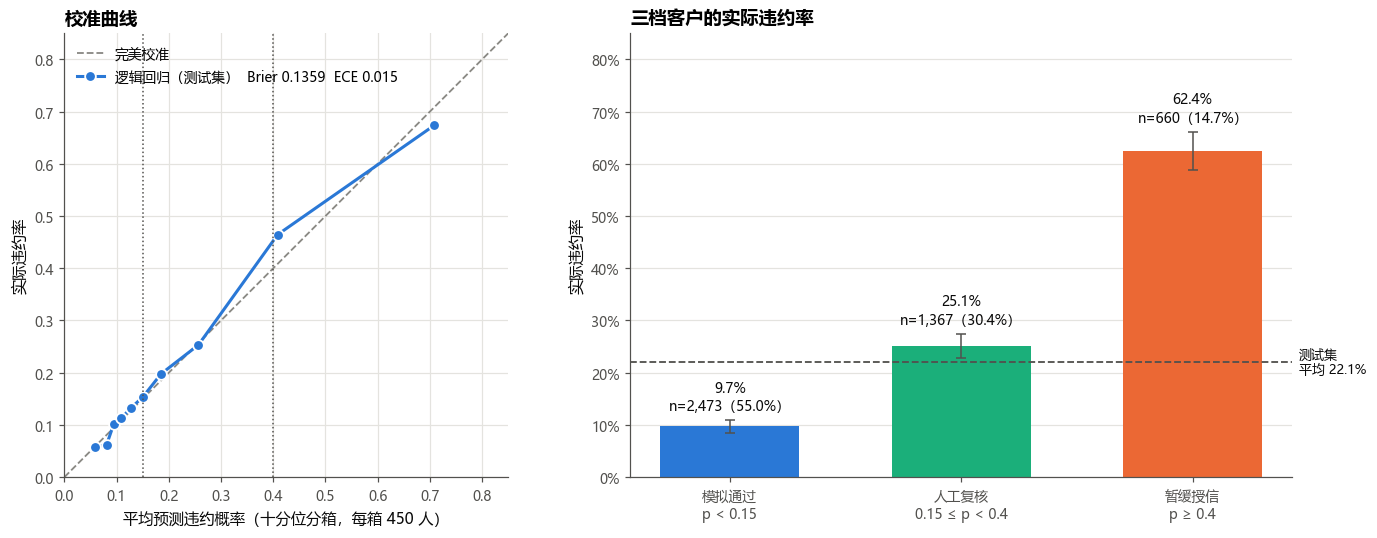

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axs[0]; t = pd.DataFrame(T["calibration"])
ax.plot([0, 1], [0, 1], color=GRAY, lw=1.2, ls="--", label="完美校准")
ax.plot(t["mean_p"], t["obs"], color=BLUE, lw=2, marker="o", ms=7, mec="white", mew=1.2,
        label=f"逻辑回归（测试集）  Brier {m['brier']:.4f}  ECE {m['ece']:.3f}")
for x in (T1, T2): ax.axvline(x, color=MUTED, lw=1, ls=":")
ax.set(xlim=(0, 0.85), ylim=(0, 0.85), xlabel="平均预测违约概率（十分位分箱，每箱 450 人）", ylabel="实际违约率", aspect="equal")
ax.set_title("校准曲线", loc="left"); ax.legend(loc="upper left", fontsize=9)

ax = axs[1]; pol = T["policy"]
names = [f"模拟通过\np < {T1}", f"人工复核\n{T1} ≤ p < {T2}", f"暂缓授信\np ≥ {T2}"]
keys, cols = ["pass", "review", "suspend"], [BLUE, AQUA, ORANGE]
v = [pol[f"{k}_default_rate"] for k in keys]; n = [pol[f"n_{k}"] for k in keys]
err = [1.96 * np.sqrt(x * (1 - x) / k) for x, k in zip(v, n)]
ax.bar(names, v, color=cols, width=0.6, yerr=err, error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=3))
for i, (x, k, e) in enumerate(zip(v, n, err)):
    ax.text(i, x + e + 0.012, f"{x:.1%}\nn={k:,}（{k / pol['n']:.1%}）", ha="center", va="bottom", fontsize=9, color=INK)
ax.axhline(T["default_rate"], color=MUTED, lw=1.2, ls="--")
ax.text(1.01, T["default_rate"], f"测试集\n平均 {T['default_rate']:.1%}", transform=ax.get_yaxis_transform(), fontsize=8.5, va="center", color=INK)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.85); ax.grid(axis="x", visible=False)
ax.set_ylabel("实际违约率"); ax.set_title("三档客户的实际违约率", loc="left")
fig.tight_layout(); save(fig, "fig15_test_calibration_tiers"); plt.show()

## 表 3 与图 16 测试集分组审计（性别、年龄段）

In [8]:
A = pd.DataFrame(T["audit"])
A[["dimension", "group", "n", "defaults", "default_rate", "mean_pd", "pass_rate", "review_rate", "suspend_rate",
   "pass_default_rate", "false_block_rate", "miss_rate", "leak_rate", "small_sample"]].round(3)

,dimension,group,n,defaults,default_rate,mean_pd,pass_rate,review_rate,suspend_rate,pass_default_rate,false_block_rate,miss_rate,leak_rate,small_sample
0,性别,男,1796,430,0.239,0.228,0.524,0.311,0.165,0.106,0.086,0.584,0.233,False
1,性别,女,2704,565,0.209,0.211,0.566,0.299,0.135,0.091,0.061,0.588,0.248,False
2,年龄段,21–29,1457,321,0.220,0.224,0.552,0.286,0.162,0.088,0.079,0.545,0.221,False
3,年龄段,30–39,1612,326,0.202,0.202,0.592,0.282,0.126,0.094,0.068,0.644,0.276,False
4,年龄段,40–49,1009,242,0.240,0.223,0.523,0.330,0.147,0.110,0.060,0.579,0.240,False
5,年龄段,50–59,360,84,0.233,0.246,0.453,0.375,0.172,0.104,0.083,0.536,0.202,False
6,年龄段,60+,62,22,0.355,0.258,0.387,0.435,0.177,0.167,0.050,0.591,0.182,True


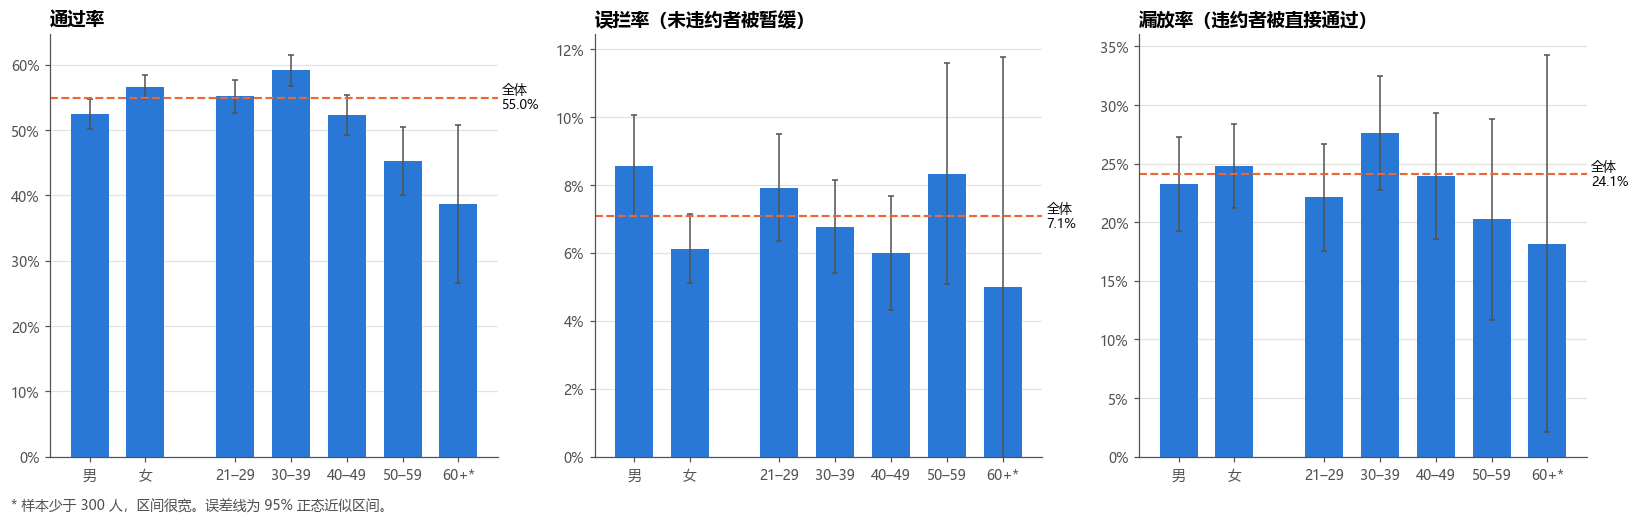

In [9]:
A["label"] = A["group"] + np.where(A["small_sample"], "*", "")
overall = T["policy"]
panels = [("pass_rate", "通过率", A["n"], overall["pass_rate"]),
          ("false_block_rate", "误拦率（未违约者被暂缓）", A["n"] - A["defaults"], overall["false_block_rate"]),
          ("leak_rate", "漏放率（违约者被直接通过）", A["defaults"], overall["leak_rate"])]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
x = np.array([0, 1, 2.6, 3.6, 4.6, 5.6, 6.6])
for ax, (col, title, den, ov) in zip(axs, panels):
    v = A[col].to_numpy(float); e = 1.96 * np.sqrt(v * (1 - v) / den.to_numpy(float))
    ax.bar(x, v, width=0.68, color=BLUE, yerr=e, error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=2))
    ax.axhline(ov, color=ORANGE, lw=1.4, ls="--")
    ax.text(1.01, ov, f"全体\n{ov:.1%}", transform=ax.get_yaxis_transform(), fontsize=8.5, va="center", color=INK)
    ax.set_xticks(x, A["label"]); ax.yaxis.set_major_formatter(pct); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, None); ax.set_title(title, loc="left")
fig.text(0.01, -0.02, "* 样本少于 300 人，区间很宽。误差线为 95% 正态近似区间。", fontsize=9, color=MUTED)
fig.tight_layout(); save(fig, "fig16_audit"); plt.show()